<a href="https://colab.research.google.com/github/Murcha1990/HSE_FitPredict_AI_School/blob/main/ML/18_11/01_demo_california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Деревья, случайный лес и бустинг: демонстрация

**Датасет:** California Housing: цены домов в районах Калифорнии по переписи 1990 года.
В отличие от версии из `sklearn`, здесь есть **категориальный признак** и **пропуски**.

In [1]:
import tarfile
import urllib.request
from pathlib import Path
from time import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (9, 4)

# Часть I. Дерево, лес и бустинг из коробки

## 1. Данные

In [2]:
def load_housing():
    path = Path('datasets/housing/housing.csv')
    if not path.is_file():
        Path('datasets').mkdir(exist_ok=True)
        tgz = Path('datasets/housing.tgz')
        urllib.request.urlretrieve('https://github.com/ageron/data/raw/main/housing.tgz', tgz)
        with tarfile.open(tgz) as f:
            f.extractall('datasets')
    return pd.read_csv(path)

housing = load_housing()
print(housing.shape)
housing.head()

(20640, 10)


/tmp/ipykernel_1836/3723296759.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  f.extractall('datasets')


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
print('Пропуски:')
print(housing.isna().sum()[housing.isna().sum() > 0])
print()
print(housing['ocean_proximity'].value_counts())

Пропуски:
total_bedrooms    207
dtype: int64

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


**На что обратить внимание**

- В `total_bedrooms` есть пропуски — классическому бустингу из sklearn их нужно заполнить.
- `ocean_proximity` — строковый категориальный признак, для sklearn его нужно закодировать.
- Категория `ISLAND` встречается всего несколько раз.
- Цена и возраст дома **обрезаны сверху** (см. гистограммы ниже): все дома дороже $500 000 записаны как 500 001. Модель не сможет предсказать больше этого значения.

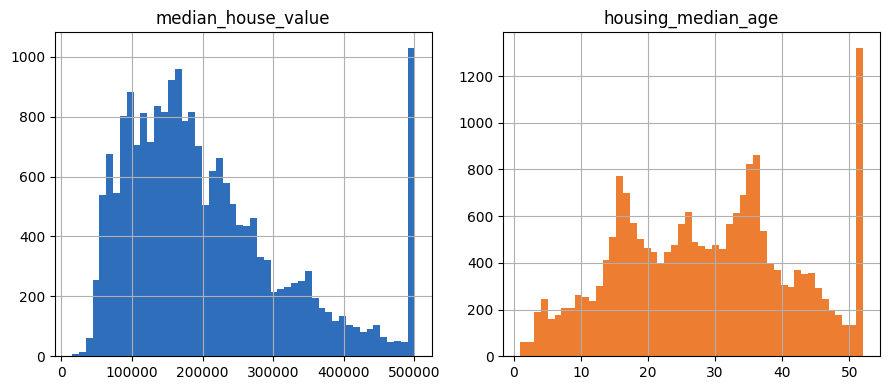

In [5]:
fig, axes = plt.subplots(1, 2)
housing['median_house_value'].hist(bins=50, ax=axes[0], color='#2F6EBA')
axes[0].set_title('median_house_value')
housing['housing_median_age'].hist(bins=50, ax=axes[1], color='#ED7D31')
axes[1].set_title('housing_median_age')
plt.tight_layout()

## 2. Разбиение и предобработка

Деревьям **не нужно масштабирование** признаков. Нужно только заполнить пропуски и закодировать категориальный признак.

In [6]:
target = 'median_house_value'
X = housing.drop(columns=target)
y = housing[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

cat_cols = ['ocean_proximity']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

print(X_train.shape, X_test.shape)

(16512, 9) (4128, 9)


In [7]:
def evaluate(name, model, results):
    t = time()
    model.fit(X_train, y_train)
    fit_time = time() - t

    rmse_train = root_mean_squared_error(y_train, model.predict(X_train))
    rmse_test = root_mean_squared_error(y_test, model.predict(X_test))

    results.append({
        'модель': name,
        'RMSE train': round(rmse_train),
        'RMSE test': round(rmse_test),
        'R² test': round(r2_score(y_test, model.predict(X_test)), 3),
        'test / train': round(rmse_test / rmse_train, 2) if rmse_train > 1 else np.inf,
        'время, с': round(fit_time, 1),
    })
    return model


def make_pipe(model):
    return Pipeline([('prep', preprocess), ('model', model)])

## 3. Эксперимент 1: параметры по умолчанию

Какая модель сильнее всего переобучится? У какой будет лучшее качество на тесте?

In [8]:
models_default = {
    'Дерево': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Случайный лес': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    'Градиентный бустинг': GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results_default = []
fitted_default = {}
for name, model in models_default.items():
    fitted_default[name] = evaluate(name, make_pipe(model), results_default)

table_default = pd.DataFrame(results_default).set_index('модель')
table_default

,RMSE train,RMSE test,R² test,test / train,"время, с"
модель,,,,,
Дерево,0,68543,0.661,inf,0.3
Случайный лес,18235,49499,0.823,2.71,13.1
Градиентный бустинг,53326,56797,0.767,1.07,3.9


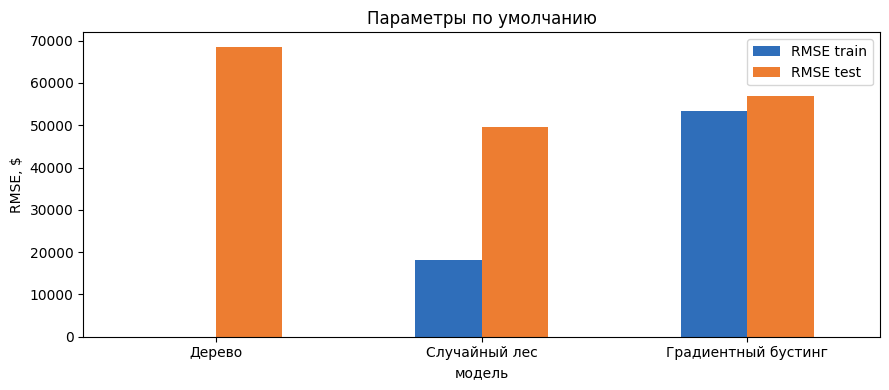

In [9]:
def plot_train_test(table, title):
    ax = table[['RMSE train', 'RMSE test']].plot.bar(color=['#2F6EBA', '#ED7D31'], rot=0)
    ax.set_ylabel('RMSE, $')
    ax.set_title(title)
    plt.tight_layout()

plot_train_test(table_default, 'Параметры по умолчанию')

**Что видно**

- **Дерево** по умолчанию растёт до конца: ошибка на train почти нулевая, на test — самая большая. Это переобучение в чистом виде: большой разброс.
- **Случайный лес** тоже почти запоминает train (деревья в нём глубокие), но на test он заметно лучше одного дерева: усреднение уменьшает разброс.
- **Бустинг** по умолчанию — 100 неглубоких деревьев (глубина 3). Ошибки на train и test близки: переобучения мало, зато модель может **недообучаться**, и её качество часто хуже леса.

Отношение «test / train» — простой индикатор переобучения: чем оно больше 1, тем сильнее модель запомнила обучающую выборку.

## 4. Эксперимент 2: подбор гиперпараметров

Подбираем параметры **только по train** с кросс-валидацией (`GridSearchCV`), а test используем один раз — для итоговой оценки.

Сетки небольшие, чтобы всё посчиталось за несколько минут. На занятии можно запустить эту ячейку заранее.

In [30]:
!pip install tqdm

In [13]:
from tqdm import tqdm


param_grids = {
    'Дерево': (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {'model__max_depth': [6, 8, 10, 12, 15, None],
         'model__min_samples_leaf': [1, 5, 10, 20, 50]},
    ),
    'Случайный лес': (
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
        {'model__max_features': [0.33, 0.5, 1.0],
         'model__min_samples_leaf': [1, 3, 5]},
    ),
    'Градиентный бустинг': (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {'model__n_estimators': [200, 500],
         'model__learning_rate': [0.05, 0.1],
         'model__max_depth': [3, 5],
         'model__subsample': [0.8]},
    ),
}

searches = {}
for name, (model, grid) in tqdm(param_grids.items()):
    t = time()
    search = GridSearchCV(make_pipe(model), grid, cv=3,
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: {time() - t:.0f} с, CV RMSE = {-search.best_score_:.0f}')
    print('   ', {k.replace('model__', ''): v for k, v in search.best_params_.items()})

 33%|███▎      | 1/3 [00:21<00:42, 21.01s/it]

Дерево: 21 с, CV RMSE = 58797
    {'max_depth': None, 'min_samples_leaf': 10}


 67%|██████▋   | 2/3 [04:24<02:31, 152.00s/it]

Случайный лес: 244 с, CV RMSE = 49476
    {'max_features': 0.5, 'min_samples_leaf': 1}


100%|██████████| 3/3 [08:04<00:00, 161.61s/it]

Градиентный бустинг: 220 с, CV RMSE = 46871
    {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.8}


In [14]:
results_tuned = []
for name, search in searches.items():
    # refit=True: лучшая модель уже переобучена на всём train
    evaluate(name, search.best_estimator_, results_tuned)

table_tuned = pd.DataFrame(results_tuned).set_index('модель')
table_tuned

,RMSE train,RMSE test,R² test,test / train,"время, с"
модель,,,,,
Дерево,41794,57757,0.759,1.38,0.2
Случайный лес,17774,48953,0.827,2.75,14.1
Градиентный бустинг,27954,46778,0.842,1.67,27.8


In [15]:
comparison = pd.DataFrame({
    'RMSE test (по умолчанию)': table_default['RMSE test'],
    'RMSE test (подбор)': table_tuned['RMSE test'],
    'test / train (по умолчанию)': table_default['test / train'],
    'test / train (подбор)': table_tuned['test / train'],
})
comparison['улучшение на test, %'] = (
    100 * (1 - comparison['RMSE test (подбор)'] / comparison['RMSE test (по умолчанию)'])).round(1)
comparison

,RMSE test (по умолчанию),RMSE test (подбор),test / train (по умолчанию),test / train (подбор),"улучшение на test, %"
модель,,,,,
Дерево,68543,57757,inf,1.38,15.7
Случайный лес,49499,48953,2.71,2.75,1.1
Градиентный бустинг,56797,46778,1.07,1.67,17.6


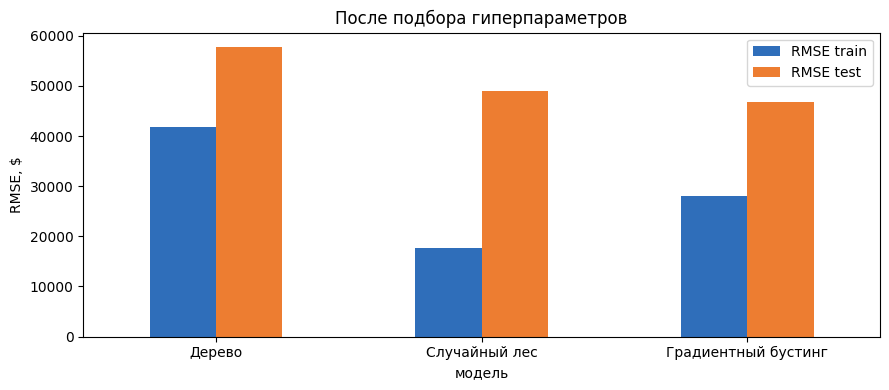

In [17]:
plot_train_test(table_tuned, 'После подбора гиперпараметров')

**Выводы, которые стоит проговорить**

- **Дерево:** ограничение глубины и минимального размера листа сильнее всего уменьшает переобучение. Ошибка на train растёт, на test — падает.
- **Лес:** выигрыш от подбора обычно небольшой — лес хорошо работает и с параметрами по умолчанию. Подбор `max_features` делает деревья менее похожими.
- **Бустинг:** больше деревьев и чуть более глубокие деревья убирают недообучение. Бустинг часто обходит лес, но разрыв между train и test у него растёт — за этим нужно следить.
- Сравнивайте модели по test только **после** того, как параметры выбраны по train. Иначе оценка качества будет завышенной.

# Часть II. CatBoost

Что меняется по сравнению со sklearn:

- категориальные признаки передаём **как есть**, кодирование CatBoost делает сам (статистики по перестановкам);
- пропуски в числовых признаках обрабатываются автоматически;
- хорошие параметры по умолчанию;
- **ранняя остановка** по валидационной выборке.

Важно: в **категориальных** признаках пропусков быть не должно — заполните их строкой, например `'Missing'`.

In [24]:
!pip install catboost -q   # если библиотеки нет

from catboost import CatBoostRegressor

In [27]:
def to_cb(X):
    X = X.copy()
    # Категориальный признак: пропуски CatBoost не принимает, поэтому заполняем их строкой.
    # В ocean_proximity пропусков нет, но так код не сломается на других данных.
    X['ocean_proximity'] = X['ocean_proximity'].astype(object).fillna('Missing')
    # Числовые пропуски (total_bedrooms) специально НЕ заполняем:
    # CatBoost обрабатывает их сам.

    return X


# Валидационную выборку для ранней остановки отрезаем от train, test не трогаем
X_tr, X_val, y_tr, y_val = train_test_split(
    to_cb(X_train), y_train, test_size=0.2, random_state=RANDOM_STATE)

cb = CatBoostRegressor(
    iterations=3000,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    random_seed=RANDOM_STATE,
    verbose=300,
)
t = time()
cb.fit(X_tr, y_tr,
       cat_features=cat_cols,          # строковый признак без кодирования
       eval_set=(X_val, y_val),
       early_stopping_rounds=200,
       use_best_model=True)
cb_time = time() - t
print('Лучшая итерация:', cb.get_best_iteration())

0:	learn: 111196.9337668	test: 112777.0109994	best: 112777.0109994 (0)	total: 44.9ms	remaining: 2m 14s
300:	learn: 46754.4608051	test: 48877.5316968	best: 48877.5316968 (300)	total: 3.92s	remaining: 35.1s
600:	learn: 41142.9597763	test: 46606.4878543	best: 46603.8284680 (599)	total: 5.98s	remaining: 23.9s
900:	learn: 37927.0779414	test: 45645.9981229	best: 45645.2525279 (897)	total: 8.14s	remaining: 19s
1200:	learn: 35474.1206418	test: 45082.3507602	best: 45082.3507602 (1200)	total: 10.2s	remaining: 15.3s
1500:	learn: 33437.7676697	test: 44764.9566142	best: 44764.4245376 (1497)	total: 13.5s	remaining: 13.5s
1800:	learn: 31682.9755456	test: 44615.7384799	best: 44614.5632841 (1799)	total: 15.7s	remaining: 10.4s
2100:	learn: 30225.5759446	test: 44453.4358258	best: 44451.3531218 (2098)	total: 17.7s	remaining: 7.59s
2400:	learn: 28975.8127441	test: 44371.3134586	best: 44353.5010424 (2352)	total: 19.8s	remaining: 4.94s
2700:	learn: 27801.5352195	test: 44261.3078295	best: 44253.5363996 (2689)

In [28]:
rmse_train = root_mean_squared_error(y_train, cb.predict(to_cb(X_train)))
rmse_test = root_mean_squared_error(y_test, cb.predict(to_cb(X_test)))
row = pd.DataFrame([{
    'модель': 'CatBoost', 'RMSE train': round(rmse_train), 'RMSE test': round(rmse_test),
    'R² test': round(r2_score(y_test, cb.predict(to_cb(X_test))), 3),
    'test / train': round(rmse_test / rmse_train, 2), 'время, с': round(cb_time, 1),
}]).set_index('модель')

final = pd.concat([table_tuned, row])
final

,RMSE train,RMSE test,R² test,test / train,"время, с"
модель,,,,,
Дерево,41794,57757,0.759,1.38,0.2
Случайный лес,17774,48953,0.827,2.75,14.1
Градиентный бустинг,27954,46778,0.842,1.67,27.8
CatBoost,31174,45258,0.852,1.45,25.1


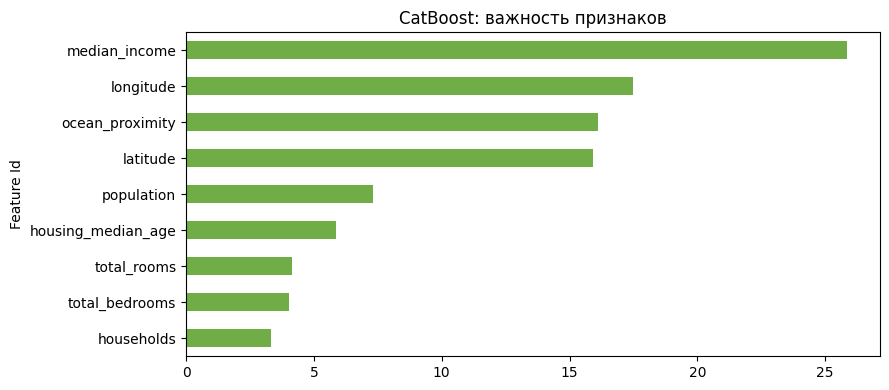

In [29]:
importance = cb.get_feature_importance(prettified=True)
ax = importance.set_index('Feature Id')['Importances'].sort_values().plot.barh(color='#70AD47')
ax.set_title('CatBoost: важность признаков')
plt.tight_layout()

**Что обсудить**

- Без какой-либо предобработки и почти без подбора параметров CatBoost обычно не уступает настроенному бустингу из sklearn.
- Ранняя остановка сама выбирает число деревьев: следим за ошибкой на валидации и останавливаемся, когда она перестаёт падать.
- Самые важные признаки — доход, координаты и `ocean_proximity`. Это хороший момент, чтобы предложить идеи новых признаков: комнат на домохозяйство, людей на домохозяйство и т. п.